In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
import copy
import gc
import joblib

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from utils import get_opt, get_loaders
from predictor_definitions import LinearRegression, LogisticRegression, MLPRegressor, MLPClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, roc_auc_score, roc_curve, mean_squared_error

In [2]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

In [3]:
layers_to_keep = (0, 1, 23)

# Loading

## Model

In [4]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
# model_name = "HuggingFaceTB/SmolLM2-360M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Data

In [5]:
n_samples = 16

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


## Stored results

In [6]:
# # rel_norms_L1_q = pd.read_csv('results/rel_norms_L1_q.csv', index_col=0)
# rel_norms_L1_q = pd.read_csv('results/quantiles_v2.csv', index_col=0)
# for i, layer in enumerate(model.model.layers):
#     mlp = layer.mlp
#     mlp.threshold = rel_norms_L1_q.iloc[i, 0]

# Collecting data and training routers

## Preparing data

In [6]:
def split_data(X, y_cls, val_size=0.15, test_size=0.15, verbose=True):
    X_temp, X_test, y_cls_temp, y_cls_test = train_test_split(
        X, y_cls, test_size=test_size, random_state=42
    )
    val_adjusted_size = val_size / (1 - test_size)
    X_train, X_val, y_cls_train, y_cls_val = train_test_split(
        X_temp, y_cls_temp, test_size=val_adjusted_size, random_state=42
    )
    
    if verbose:
        print(f"Train set: {X_train.shape[0]} samples")
        print(f"Validation set: {X_val.shape[0]} samples")
        print(f"Test set: {X_test.shape[0]} samples")

    # Convert to PyTorch tensors
    X_train_tensor = torch.FloatTensor(X_train.values)
    X_val_tensor = torch.FloatTensor(X_val.values)
    X_test_tensor = torch.FloatTensor(X_test.values)

    y_cls_train_tensor = torch.FloatTensor(y_cls_train.reshape(-1, 1))
    y_cls_val_tensor = torch.FloatTensor(y_cls_val.reshape(-1, 1))
    y_cls_test_tensor = torch.FloatTensor(y_cls_test.reshape(-1, 1))

    return {
        'X_train': X_train_tensor, 'X_val': X_val_tensor, 'X_test': X_test_tensor,
        'y_cls_train': y_cls_train_tensor, 'y_cls_val': y_cls_val_tensor, 'y_cls_test': y_cls_test_tensor
    }

## Routers

### Eval functions

In [7]:
def evaluate_regression(model, data_dict, verbose=True):
    with torch.no_grad():
        y_pred = model.predict(data_dict['X_test'].to(DEV)).cpu().numpy()
        y_true = data_dict['y_reg_test'].numpy()
        if np.isnan(y_pred).any():
            return {'R2': np.nan, 'MSE': np.nan}
        r2 = r2_score(y_true, y_pred)
        mse = np.mean((y_true - y_pred) ** 2)
        if verbose:
            print("\nLinear Regression Model Evaluation:")
            print(f"R² Score: {r2:.4f}")
            print(f"MSE: {mse:.4f}")

            # Plot predictions vs actual
            plt.figure(figsize=(10, 6))
            plt.scatter(y_true, y_pred, alpha=0.5)
            plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--')
            plt.xlabel('Actual Values')
            plt.ylabel('Predicted Values')
            plt.title('Linear Regression: Predicted vs Actual')
            plt.show()
        return {'R2': r2, 'MSE': mse}

def evaluate_classification(model, data_dict, verbose=True):
    with torch.no_grad():
        y_pred = model.predict(data_dict['X_test'].to(DEV)).cpu().numpy()
        y_true = data_dict['y_cls_test'].numpy()
        
        auc = roc_auc_score(y_true, y_pred) if len(np.unique(y_true)) > 1 else np.nan
        accuracy = np.mean(y_pred == y_true)

        if verbose:
            print("\nLogistic Regression Model Evaluation:")
            print(f"AUC Score: {auc:.4f}")
            print(f"Accuracy: {accuracy:.4f}")

            fpr, tpr, _ = roc_curve(y_true, y_pred_proba)

            plt.figure(figsize=(10, 6))
            plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
            plt.plot([0, 1], [0, 1], 'k--')
            plt.xlabel('False Positive Rate')
            plt.ylabel('True Positive Rate')
            plt.title('ROC Curve - Logistic Regression')
            plt.legend()
            plt.show()

        return {'AUC': auc, 'Accuracy': accuracy}

### Train layer predictor

In [8]:
def train_predictors(data_dict, classifier, results, i, 
                    label='', predictor_dir='predictors_v2',
                    cls_lrs=(100, 10, 1, 1e-1, 1e-2, 1e-3)):
    best_auc = float('-inf')
    best_cls_lr, best_cls_model = None, None
    os.makedirs(predictor_dir, exist_ok=True)

    # Try different learning rates for classification (only if more than one class present)
    if len(np.unique(data_dict['y_cls_train'])) > 1:
        for lr in cls_lrs:
            print_line = f"learning_rate={lr:<6} | "
            cls_model = classifier(lr)
            cls_model.fit(data_dict['X_train'].to(DEV), data_dict['y_cls_train'].to(DEV),
                          data_dict['X_val'].to(DEV), data_dict['y_cls_val'].to(DEV))
            if cls_model:
                cls_metrics = evaluate_classification(cls_model, data_dict, verbose=False)
                auc = format_num(cls_metrics['AUC'])
                print_line += f"AUC={color_auc(auc)}"
                if cls_metrics['AUC'] > best_auc:
                    best_auc = cls_metrics['AUC']
                    best_cls_model = cls_model
                    best_cls_lr = lr
            print(print_line)

    # Save best models
    auc = 0.5
    if best_cls_model is not None:
        auc = best_auc
        save_path = f"{predictor_dir}/cls_model_{label}_layer{i}.pkl"
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        joblib.dump(best_cls_model, save_path)

    results.loc[i] = [best_cls_lr, auc]
    return best_cls_model, results


### Output format

In [9]:
def format_num(val, chars=5):
    s = f"{val}"
    return s[:chars].rjust(chars) if len(s) > chars else s.rjust(chars)

def color_r2(x):
    if float(x) < 0:
        return f"\033[91m{x}\033[0m"  # Red
    elif float(x) < 0.5:
        return f"\033[93m{x}\033[0m"  # Yellow
    else:
        return x

def color_auc(x):
    if float(x) < 0.5:
        return f"\033[91m{x}\033[0m"  # Red
    if float(x) < 0.75:
        return f"\033[93m{x}\033[0m"  # Yellow
    else:
        return x

### Router setup

In [10]:
def rel_L1_norm(inps_abs, outs_abs):
    return outs_abs.sum(dim=2, keepdim=True) / inps_abs.sum(dim=2, keepdim=True)

def capture_inputs_and_norms(module, inps, outs):
    outs_abs = outs.abs()
    inps_abs = inps[0].abs()
    token_norms = rel_L1_norm(inps_abs, outs_abs)

    module.inputs.extend(inps[0][0].detach().cpu().float().tolist())
    module.y_norms.extend(token_norms.flatten().detach().cpu().float().tolist())

    return outs      # no need for masking - later layers dont matter now

In [11]:
class MLPRouter(nn.Module):
    def __init__(self, predictor, mlp, save_bitmap=False):
        super().__init__()
        self.predictor = predictor
        self.mlp = mlp
        self.n_total = 0
        self.n_mlp = 0
        self.save_bitmap = save_bitmap
        if save_bitmap:
            self.bitmap = []
        
    def forward(self, x):
        use_mlp = self.predictor.predict(x.to(torch.float).squeeze(0)).bool()
        bsz, seq_len, dim = x.shape
        x_flat = x.view(-1, dim)
        use_mlp_flat = use_mlp.flatten()  # shape: (bsz * seq_len)
        self.n_mlp += use_mlp_flat.sum()
        self.n_total += use_mlp_flat.size(0)
        # Apply MLP only to selected tokens
        out = torch.zeros_like(x_flat)  # same shape as input
        if use_mlp_flat.any():
            selected = x_flat[use_mlp_flat]  # (N_selected, dim)
            mlp_out = self.mlp(selected)     # (N_selected, dim)
            out[use_mlp_flat] = mlp_out      # insert results
            if self.save_bitmap:
                self.bitmap.extend(use_mlp_flat.tolist())

        return out.view(bsz, seq_len, dim)

### Main function

In [12]:
# @torch.no_grad()
def collect_and_train(model, dataloader, classifier_class, cls_lrs=(100, 10, 1, 1e-1, 1e-2, 1e-3), 
                      label='', save_dir="mlp_data_v2"):
    use_cache = model.config.use_cache
    model.config.use_cache = False

    os.makedirs(save_dir, exist_ok=True)
    
    quantiles = pd.DataFrame(columns=['0.3'])
    results = pd.DataFrame(columns=['learning_rate', 'AUC'])

    for i, layer in enumerate(model.model.layers):
        if i in layers_to_keep: continue

        print('Layer', i)
        mlp = model.model.layers[i].mlp
        mlp.inputs, mlp.y_norms, mlp.y_bin = [], [], []
        mlp.h = mlp.register_forward_hook(capture_inputs_and_norms)

        for j in range(n_samples):
            model(dataloader[j][0].to(DEV))
    
        gc.collect()
        torch.cuda.empty_cache()

        mlp.h.remove()

        mlp.inputs = torch.Tensor(mlp.inputs)
        mlp.y_norms = torch.Tensor(mlp.y_norms)
        
        mlp.threshold = np.quantile(mlp.y_norms, 0.3)
        quantiles.loc[i] = [mlp.threshold]
        mask = mlp.y_norms >= mlp.threshold
        
        mlp.y_bin = mask.flatten().detach().cpu().float()

        # Combine into a single DataFrame
        df = pd.DataFrame(mlp.inputs)
        df['y_norm'] = mlp.y_norms
        df['y_bin'] = mlp.y_bin
        df.columns = df.columns.map(str)
        del mlp.inputs, mlp.y_norms, mlp.y_bin

        # Save to parquet
        save_path = os.path.join(save_dir, f"layer_{i}.parquet")
        df.to_parquet(save_path, compression="zstd")
        print(f"saved data to {save_path}")

        # use df to train
        # prepare data
        X = df.drop(['y_norm', 'y_bin'], axis=1)
        y_cls = df['y_bin'].values  # Regression target
        data_dict = split_data(X, y_cls, verbose=False)
        
        classifier, results = train_predictors(
            data_dict=data_dict, results=results, i=i, 
            classifier=classifier_class, cls_lrs=cls_lrs,
            label=label, predictor_dir='predictors_rel_L1_v2')
        
        if not hasattr(layer, "predictor"): 
            layer.predictor = {}
        layer.predictor[label] = classifier 
        mlp_copy = copy.deepcopy(layer.mlp)
        layer.mlp = MLPRouter(classifier, mlp_copy)
        print()
        
    model.config.use_cache = use_cache
    quantiles.to_csv(f'results/quantiles_v2_{label}.csv')
    return results

In [14]:
results_lr = collect_and_train(
    model, dataloader, LogisticRegression, cls_lrs=(100, 10, 1, 1e-1), 
    label='lr', save_dir='mlp_data_v2')

Layer 2
saved data to mlp_data_v2/layer_2.parquet
learning_rate=100    | AUC=0.891
learning_rate=10     | AUC=0.891
learning_rate=1      | AUC=0.883
learning_rate=0.1    | AUC=0.846

Layer 3
saved data to mlp_data_v2/layer_3.parquet
learning_rate=100    | AUC=0.910
learning_rate=10     | AUC=0.911
learning_rate=1      | AUC=0.899
learning_rate=0.1    | AUC=0.862

Layer 4
saved data to mlp_data_v2/layer_4.parquet
learning_rate=100    | AUC=0.872
learning_rate=10     | AUC=0.871
learning_rate=1      | AUC=0.858
learning_rate=0.1    | AUC=0.799

Layer 5
saved data to mlp_data_v2/layer_5.parquet
learning_rate=100    | AUC=0.815
learning_rate=10     | AUC=0.814
learning_rate=1      | AUC=0.806
learning_rate=0.1    | AUC=0.758

Layer 6
saved data to mlp_data_v2/layer_6.parquet
learning_rate=100    | AUC=0.822
learning_rate=10     | AUC=0.823
learning_rate=1      | AUC=0.810
learning_rate=0.1    | AUC=0.756

Layer 7
saved data to mlp_data_v2/layer_7.parquet
learning_rate=100    | AUC=0.812
le

In [15]:
results_lr

,learning_rate,AUC
2,100.0,0.891818
3,10.0,0.911403
4,100.0,0.872503
5,100.0,0.815247
6,10.0,0.823892
7,10.0,0.815919
8,10.0,0.835531
9,100.0,0.801283
10,10.0,0.818106
11,10.0,0.856892


In [16]:
results_lr.to_csv('results/prediction_results_v2_lr_rel_L1.csv')

In [17]:
model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

In [13]:
results_nn = collect_and_train(
    model, dataloader, MLPClassifier, cls_lrs=(100, 10, 1, 1e-1), 
    label='nn', save_dir='mlp_data_v2_nn')

Layer 2
saved data to mlp_data_v2_nn/layer_2.parquet
learning_rate=100    | AUC=0.908
learning_rate=10     | AUC=0.908
learning_rate=1      | AUC=0.897
learning_rate=0.1    | AUC=0.846

Layer 3
saved data to mlp_data_v2_nn/layer_3.parquet
learning_rate=100    | AUC=0.923
learning_rate=10     | AUC=0.924
learning_rate=1      | AUC=0.915
learning_rate=0.1    | AUC=0.875

Layer 4
saved data to mlp_data_v2_nn/layer_4.parquet
learning_rate=100    | AUC=0.890
learning_rate=10     | AUC=0.892
learning_rate=1      | AUC=0.876
learning_rate=0.1    | AUC=0.813

Layer 5
saved data to mlp_data_v2_nn/layer_5.parquet
learning_rate=100    | AUC=0.848
learning_rate=10     | AUC=0.840
learning_rate=1      | AUC=0.827
learning_rate=0.1    | AUC=0.741

Layer 6
saved data to mlp_data_v2_nn/layer_6.parquet
learning_rate=100    | AUC=0.846
learning_rate=10     | AUC=0.849
learning_rate=1      | AUC=0.833
learning_rate=0.1    | AUC=0.760

Layer 7
saved data to mlp_data_v2_nn/layer_7.parquet
learning_rate=100

In [14]:
results_nn

,learning_rate,AUC
2,10.0,0.908894
3,10.0,0.924907
4,10.0,0.892594
5,100.0,0.848535
6,10.0,0.849044
7,10.0,0.831472
8,100.0,0.849739
9,10.0,0.814981
10,10.0,0.819339
11,100.0,0.864026


In [15]:
results_nn.to_csv('results/prediction_results_v2_nn_rel_L1.csv')

# Results

In [16]:
results_lr = pd.read_csv('results/prediction_results_v2_lr_rel_L1.csv', index_col=0)
results_nn = pd.read_csv('results/prediction_results_v2_nn_rel_L1.csv', index_col=0)

In [17]:
prediction_results = pd.merge(results_lr, results_nn, right_index=True, left_index=True, suffixes=('_lr', '_nn'))
prediction_results.to_csv('results/prediction_results_v2.csv')
prediction_results

,learning_rate_lr,AUC_lr,learning_rate_nn,AUC_nn
2,100.0,0.891818,10.0,0.908894
3,10.0,0.911403,10.0,0.924907
4,100.0,0.872503,10.0,0.892594
5,100.0,0.815247,100.0,0.848535
6,10.0,0.823892,10.0,0.849044
7,10.0,0.815919,10.0,0.831472
8,10.0,0.835531,100.0,0.849739
9,100.0,0.801283,10.0,0.814981
10,10.0,0.818106,10.0,0.819339
11,10.0,0.856892,100.0,0.864026


## Visualization

In [18]:
all_results = pd.read_csv('results/prediction_results_v2.csv', index_col=0)

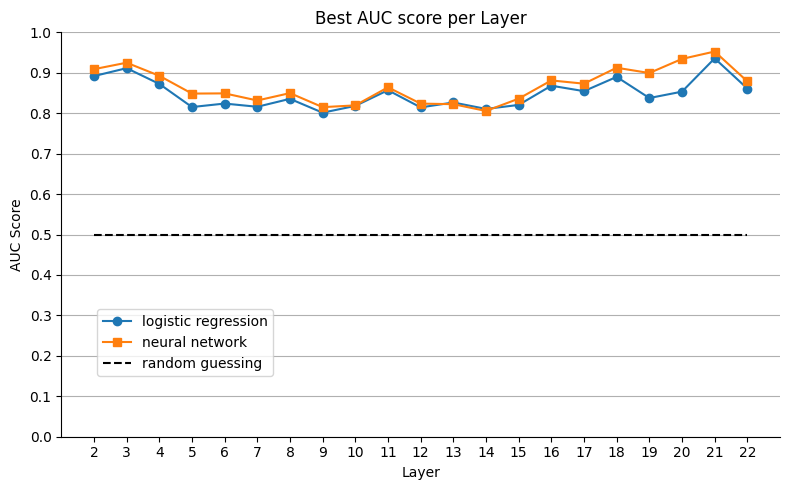

In [19]:
layers = list(all_results.index)

plt.figure(figsize=(8, 5))

plt.plot(layers, all_results['AUC_lr'], marker='o', label='logistic regression')
plt.plot(layers, all_results['AUC_nn'], marker='s', label='neural network')
plt.plot([min(layers), max(layers)], [0.5, 0.5], linestyle='--', label='random guessing', color='black')

plt.title('Best AUC score per Layer')
plt.xlabel('Layer')
plt.ylabel('AUC Score')
plt.ylim((0, 1))
plt.grid(axis='y')
plt.xticks(layers)
plt.yticks([x/10 for x in range(11)])
plt.legend(loc=(0.05, 0.15))
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()